In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. טעינת נתונים — Data Loading

בשלב זה נטען שני קובצי נתונים מרכזיים מתוך Olist Brazilian E-Commerce Dataset:

- **Orders Dataset:** מכיל פרטי הזמנות, תאריכי רכישה וסטטוס הזמנה.
- **Order Items Dataset:** מכיל פריטים שנרכשו ואת מחירי המוצרים.

מטרת השלב היא להכין את הנתונים לניתוח מגמות מכירות והכנסות לאורך זמן.

ההכנסות יחושבו על בסיס מחירי המוצרים (`price`), ללא עלויות משלוח (`freight_value`).

In [2]:
from pathlib import Path

# Define project data directory
data_path = Path("../DATA/RAW")

# Load orders dataset
orders = pd.read_csv(
    data_path / "olist_orders_dataset (7).csv"
)

# Load order items dataset
order_items = pd.read_csv(
    data_path / "olist_order_items_dataset (6).csv"
)

# Display dataset dimensions
print("Orders shape:", orders.shape)
print("Order Items shape:", order_items.shape)

# Preview orders data
display(orders.head())

# Preview order items data
display(order_items.head())

Orders shape: (99441, 8)
Order Items shape: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


## 3. בדיקות איכות נתונים — Data Validation

לפני ביצוע ניתוח מגמות המכירות, נבדוק את איכות הנתונים בשני קובצי המקור.

הבדיקות כוללות:

- בדיקת ערכים חסרים בשדות מרכזיים.
- בדיקת כפילויות במזהי הזמנות.
- בדיקת תקינות מחירי המוצרים.
- המרת תאריכי רכישה לפורמט `datetime`.
- בחינת התפלגות סטטוס ההזמנות.

מטרת הבדיקות היא להבטיח שחישובי ההכנסות והמגמות יתבססו על נתונים תקינים ועקביים.

In [3]:
# Create working copies
orders_clean = orders.copy()
items_clean = order_items.copy()

# Convert purchase date to datetime
orders_clean["order_purchase_timestamp"] = pd.to_datetime(
    orders_clean["order_purchase_timestamp"],
    errors="coerce"
)

# Check missing values in essential columns
print("===== MISSING VALUES =====")

print("\nOrders:")
print(
    orders_clean[
        ["order_id", "order_purchase_timestamp", "order_status"]
    ].isna().sum()
)

print("\nOrder Items:")
print(
    items_clean[
        ["order_id", "price"]
    ].isna().sum()
)

# Check duplicate order IDs
print("\n===== DUPLICATES =====")
print(
    "Duplicate Order IDs:",
    orders_clean["order_id"].duplicated().sum()
)

# Check invalid prices
print("\n===== INVALID PRICES =====")
print(
    "Negative Prices:",
    (items_clean["price"] < 0).sum()
)

print(
    "Zero Prices:",
    (items_clean["price"] == 0).sum()
)

# Check order statuses
print("\n===== ORDER STATUS =====")
print(orders_clean["order_status"].value_counts())

# Check purchase date range
print("\n===== DATE RANGE =====")
print(
    "First Purchase:",
    orders_clean["order_purchase_timestamp"].min()
)
print(
    "Last Purchase:",
    orders_clean["order_purchase_timestamp"].max()
)

===== MISSING VALUES =====

Orders:
order_id                    0
order_purchase_timestamp    0
order_status                0
dtype: int64

Order Items:
order_id    0
price       0
dtype: int64

===== DUPLICATES =====
Duplicate Order IDs: 0

===== INVALID PRICES =====
Negative Prices: 0
Zero Prices: 0

===== ORDER STATUS =====
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

===== DATE RANGE =====
First Purchase: 2016-09-04 21:15:19
Last Purchase: 2018-10-17 17:30:18


## 4. מיזוג נתונים — Data Merging

בשלב זה נמזג את טבלת ההזמנות (`Orders`) עם טבלת פריטי ההזמנות (`Order Items`) באמצעות השדה המשותף `order_id`.

מטרות המיזוג:

- שיוך תאריך הרכישה לכל פריט בהזמנה.
- חישוב הכנסות ממכירת מוצרים.
- הכנת הנתונים לניתוח מגמות מכירות חודשיות.
- מניעת ספירה כפולה של הזמנות הכוללות מספר פריטים.

ההכנסות יחושבו לפי `price`, ללא עלויות משלוח. לצורך ניתוח המכירות נשתמש בהזמנות שהושלמו בסטטוס `delivered`.

In [4]:
# Select delivered orders
delivered_orders = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

# Select required columns
delivered_orders = delivered_orders[
    ["order_id", "order_purchase_timestamp"]
]

# Merge orders with order items
sales_data = items_clean.merge(
    delivered_orders,
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Remove records with missing essential values
sales_data = sales_data.dropna(
    subset=["order_purchase_timestamp", "price"]
)

# Keep valid non-negative prices
sales_data = sales_data[
    sales_data["price"] >= 0
].copy()

# Create monthly period
sales_data["year_month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Display results
print("===== MERGED SALES DATA =====")
print("Total Items:", len(sales_data))
print("Unique Orders:", sales_data["order_id"].nunique())
print("Total Product Revenue: R$", round(sales_data["price"].sum(), 2))

display(sales_data.head())

===== MERGED SALES DATA =====
Total Items: 110197
Unique Orders: 96478
Total Product Revenue: R$ 13221498.11


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,year_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,2017-02


## 5. ניתוח הכנסות חודשיות — Monthly Revenue Analysis

בשלב זה נחשב את ההכנסות החודשיות, מספר ההזמנות הייחודיות וממוצע ההכנסות להזמנה.

הניתוח יאפשר לזהות:

- חודשים בעלי הכנסות גבוהות או נמוכות.
- שינויים בהיקף ההזמנות לאורך זמן.
- מגמות בצמיחת המכירות.
- שינויים בערך ההזמנה הממוצע (AOV).

In [5]:
# Aggregate sales by month
monthly_sales = (
    sales_data
    .groupby("year_month")
    .agg(
        Revenue=("price", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

# Calculate Average Order Value
monthly_sales["AOV"] = (
    monthly_sales["Revenue"] /
    monthly_sales["Orders"]
)

# Calculate Month-over-Month revenue growth
monthly_sales["Revenue_Growth_MoM"] = (
    monthly_sales["Revenue"]
    .pct_change() * 100
)

# Convert monthly period to timestamp
monthly_sales["year_month"] = (
    monthly_sales["year_month"].dt.to_timestamp()
)

# Display results
print("===== MONTHLY SALES ANALYSIS =====")
display(monthly_sales.head(12))

print("\nTotal Revenue: R$", round(monthly_sales["Revenue"].sum(), 2))
print("Total Orders:", monthly_sales["Orders"].sum())

===== MONTHLY SALES ANALYSIS =====


,year_month,Revenue,Orders,AOV,Revenue_Growth_MoM
0,2016-09-01,134.97,1,134.97,NaN
1,2016-10-01,"40,325.11",265,152.17,"29,777.09"
2,2016-12-01,10.90,1,10.90,-99.97
3,2017-01-01,"111,798.36",750,149.06,"1,025,573.03"
4,2017-02-01,"234,223.40",1653,141.70,109.51
5,2017-03-01,"359,198.85",2546,141.08,53.36
6,2017-04-01,"340,669.68",2303,147.92,-5.16
7,2017-05-01,"489,338.25",3546,138.00,43.64
8,2017-06-01,"421,923.37",3135,134.58,-13.78
9,2017-07-01,"481,604.52",3872,124.38,14.15



Total Revenue: R$ 13221498.11
Total Orders: 96478


## 6. ניתוח מגמות מכירות — Sales Trend Visualization

בשלב זה נציג את תוצאות ניתוח המכירות באמצעות גרפים.

מטרות הניתוח:

- זיהוי מגמות בעלייה או בירידה בהכנסות החודשיות.
- בחינת השינויים במספר ההזמנות לאורך זמן.
- מדידת שיעור הצמיחה החודשי (Month-over-Month Growth).
- זיהוי תקופות חריגות הדורשות בדיקה עסקית נוספת.

הניתוח מבוסס על הכנסות ממכירת מוצרים (`price`) בהזמנות שסופקו ללקוחות (`delivered`).

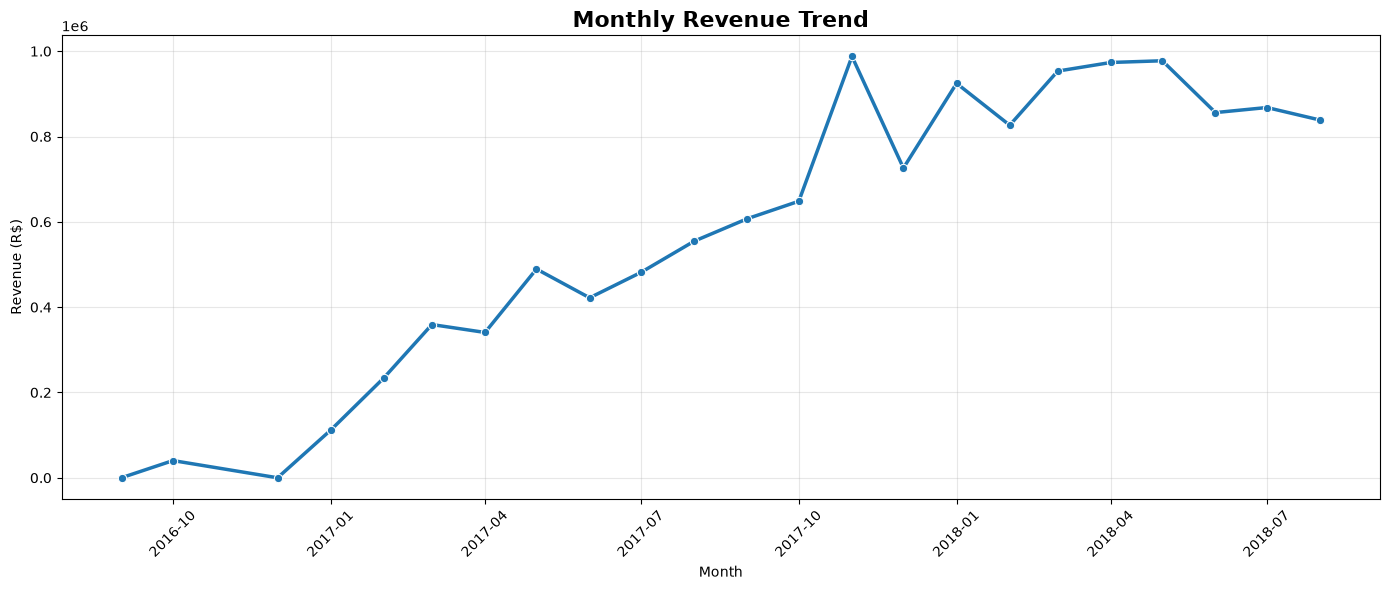

In [6]:
# Monthly Revenue Trend

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y="Revenue",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Revenue Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 7. ניתוח מגמת הזמנות חודשיות — Monthly Orders Trend

גרף זה מציג את מספר ההזמנות הייחודיות בכל חודש.

מטרת הניתוח היא לבחון האם השינויים בהכנסות נובעים משינוי בכמות ההזמנות, ולזהות חודשים שבהם נרשמה פעילות מסחרית גבוהה או נמוכה.

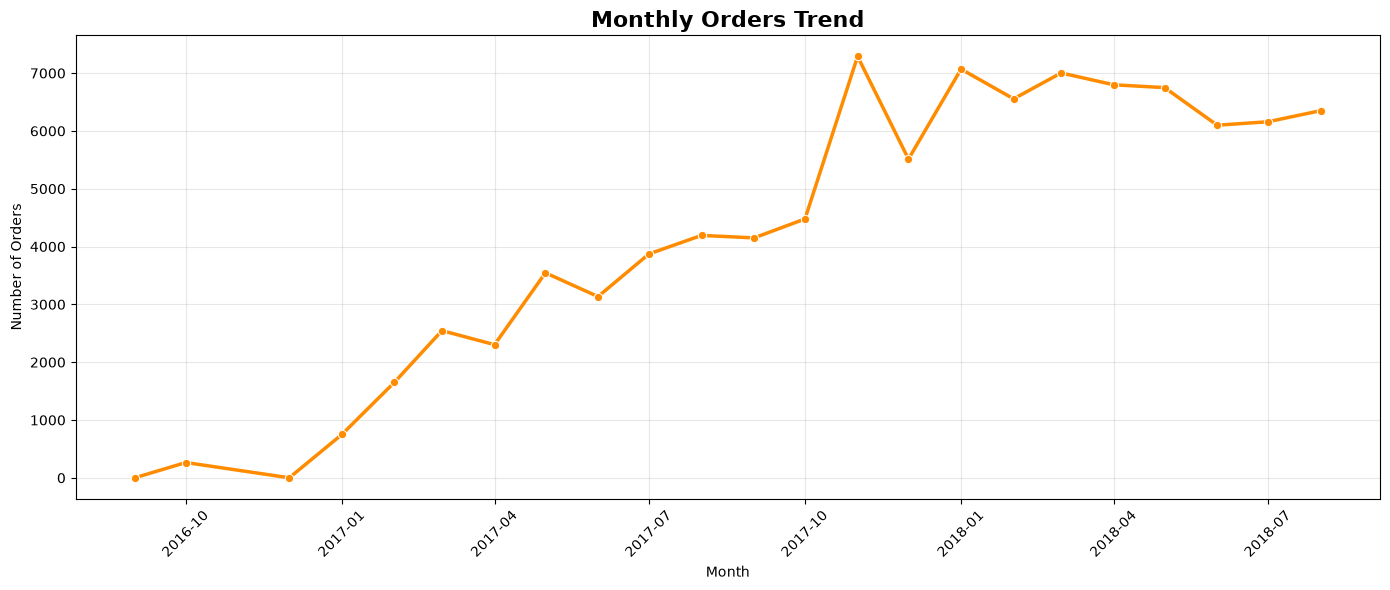

In [7]:
# Monthly Orders Trend

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y="Orders",
    marker="o",
    color="darkorange",
    linewidth=2.5
)

plt.title("Monthly Orders Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## 8. ניתוח שיעור צמיחה חודשי — Month-over-Month Revenue Growth

בשלב זה ננתח את שיעור השינוי בהכנסות בהשוואה לחודש הקודם.

- ערך חיובי מצביע על עלייה בהכנסות.
- ערך שלילי מצביע על ירידה בהכנסות.
- ערך הקרוב לאפס מצביע על יציבות יחסית.

יש להביא בחשבון שחודשים חלקיים או תקופות שבהן קיימים נתונים חסרים עלולים להשפיע על תוצאות הניתוח.

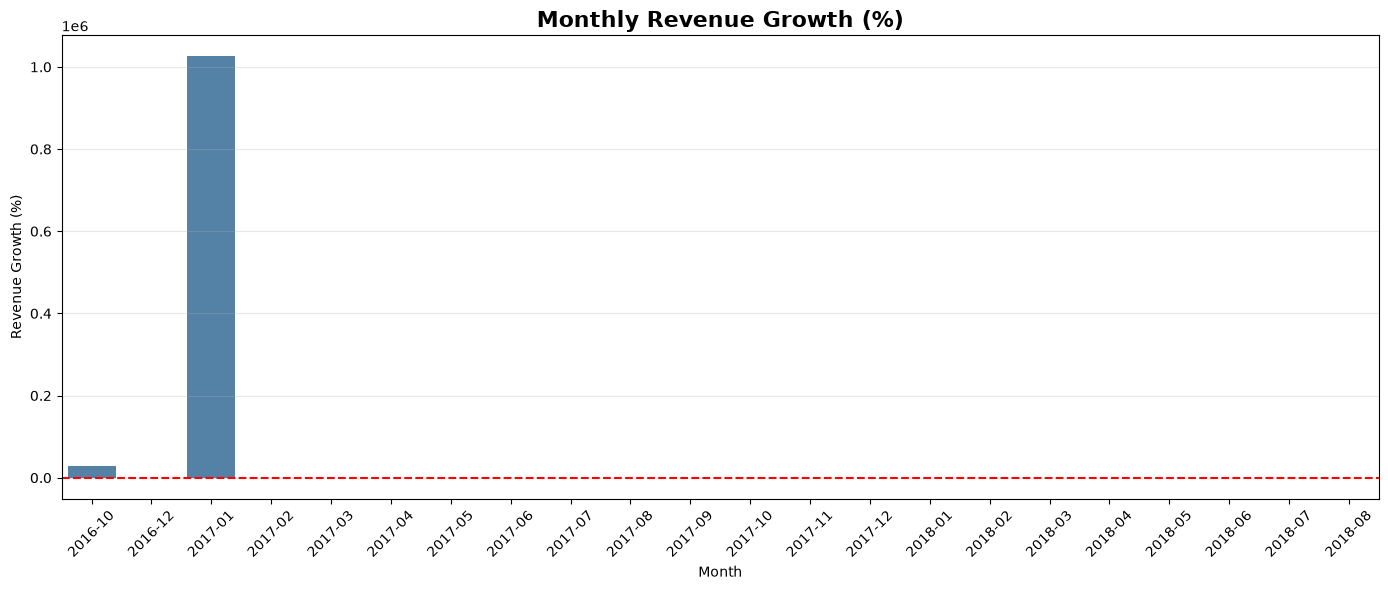

In [8]:
# Month-over-Month Revenue Growth

growth_data = monthly_sales.dropna(
    subset=["Revenue_Growth_MoM"]
).copy()

plt.figure(figsize=(14, 6))

sns.barplot(
    data=growth_data,
    x="year_month",
    y="Revenue_Growth_MoM",
    color="steelblue"
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Monthly Revenue Growth (%)", fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")
plt.xticks(
    ticks=range(len(growth_data)),
    labels=growth_data["year_month"].dt.strftime("%Y-%m"),
    rotation=45
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [9]:
# Sales Trend Summary

best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmin()
]

print("===== SALES TREND SUMMARY =====")

print(
    "Highest Revenue Month:",
    best_month["year_month"].strftime("%Y-%m")
)

print(
    "Highest Monthly Revenue: R$",
    round(best_month["Revenue"], 2)
)

print(
    "Lowest Revenue Month:",
    lowest_month["year_month"].strftime("%Y-%m")
)

print(
    "Lowest Monthly Revenue: R$",
    round(lowest_month["Revenue"], 2)
)

print(
    "Average Monthly Revenue: R$",
    round(monthly_sales["Revenue"].mean(), 2)
)

===== SALES TREND SUMMARY =====
Highest Revenue Month: 2017-11
Highest Monthly Revenue: R$ 987765.37
Lowest Revenue Month: 2016-12
Lowest Monthly Revenue: R$ 10.9
Average Monthly Revenue: R$ 574847.74


In [10]:
# Check monthly sales data quality

monthly_sales_check = monthly_sales.sort_values(
    by="year_month"
).copy()

display(
    monthly_sales_check[
        ["year_month", "Revenue", "Orders"]
    ]
)

print("Total Months:", len(monthly_sales_check))

print(
    "Total Revenue: R$",
    round(monthly_sales_check["Revenue"].sum(), 2)
)

print(
    "Months with fewer than 100 orders:",
    len(monthly_sales_check[
        monthly_sales_check["Orders"] < 100
    ])
)

,year_month,Revenue,Orders
0,2016-09-01,134.97,1
1,2016-10-01,"40,325.11",265
2,2016-12-01,10.90,1
3,2017-01-01,"111,798.36",750
4,2017-02-01,"234,223.40",1653
5,2017-03-01,"359,198.85",2546
6,2017-04-01,"340,669.68",2303
7,2017-05-01,"489,338.25",3546
8,2017-06-01,"421,923.37",3135
9,2017-07-01,"481,604.52",3872


Total Months: 23
Total Revenue: R$ 13221498.11
Months with fewer than 100 orders: 2


## 9. ממצאים ראשוניים — Sales Trend Findings

ניתוח מגמות המכירות החודשיות הצביע על הממצאים הבאים:

- **חודש השיא בהכנסות:** נובמבר 2017, עם הכנסות בסך R$ 987,765.37.
- **החודש בעל ההכנסות הנמוכות ביותר:** דצמבר 2016, עם הכנסות בסך R$ 10.90.
- **ממוצע הכנסות חודשי:** R$ 574,847.74.

### בדיקת איכות הנתונים

ההכנסות הנמוכות במיוחד בדצמבר 2016 מחייבות בדיקה נוספת של מספר ההזמנות ושל שלמות הנתונים.

לפני הסקת מסקנות עסקיות, יש לבחון האם קיימים חודשים חלקיים או חריגים המשפיעים על הממוצע ועל מגמות הצמיחה.

### משמעות עסקית

זיהוי חודשים בעלי הכנסות גבוהות עשוי לסייע בבחינת עונתיות, שינויים בביקוש והזדמנויות לתכנון פעילות מסחרית. עם זאת, נדרשת בדיקה נוספת לפני ייחוס השינויים לגורמים עסקיים מסוימים.

In [11]:
# Identify months with very low order counts

low_activity_months = monthly_sales_check[
    monthly_sales_check["Orders"] < 100
].copy()

display(
    low_activity_months[
        ["year_month", "Orders", "Revenue"]
    ]
)

# Check the complete date range
print(
    "First month:",
    monthly_sales_check["year_month"].min()
)

print(
    "Last month:",
    monthly_sales_check["year_month"].max()
)

,year_month,Orders,Revenue
0,2016-09-01,1,134.97
2,2016-12-01,1,10.90


First month: 2016-09-01 00:00:00
Last month: 2018-08-01 00:00:00


In [12]:
# Create a dataset for monthly growth analysis
# Exclude months with fewer than 100 orders

monthly_sales_growth = monthly_sales_check[
    monthly_sales_check["Orders"] >= 100
].copy()

# Sort months chronologically
monthly_sales_growth = monthly_sales_growth.sort_values(
    by="year_month"
)

# Calculate Month-over-Month revenue growth
monthly_sales_growth["MoM_Growth"] = (
    monthly_sales_growth["Revenue"].pct_change() * 100
)

# Display results
display(
    monthly_sales_growth[
        ["year_month", "Orders", "Revenue", "MoM_Growth"]
    ].round(2)
)

print(
    "Months included in growth analysis:",
    len(monthly_sales_growth)
)

C:\Users\MASTER PC\AppData\Local\Temp\ipykernel_24864\2303538416.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,year_month,Orders,Revenue,MoM_Growth
1,2016-10-01,265,"40,325.11",NaN
3,2017-01-01,750,"111,798.36",177.24
4,2017-02-01,1653,"234,223.40",109.51
5,2017-03-01,2546,"359,198.85",53.36
6,2017-04-01,2303,"340,669.68",-5.16
7,2017-05-01,3546,"489,338.25",43.64
8,2017-06-01,3135,"421,923.37",-13.78
9,2017-07-01,3872,"481,604.52",14.15
10,2017-08-01,4193,"554,699.70",15.18
11,2017-09-01,4150,"607,399.67",9.50


Months included in growth analysis: 21


## 10. ניתוח צמיחה חודשית — Month-over-Month Growth

במסגרת בדיקת איכות הנתונים זוהו שני חודשים בעלי פעילות נמוכה במיוחד:

- **ספטמבר 2016:** הזמנה אחת, הכנסות בסך R$ 134.97.
- **דצמבר 2016:** הזמנה אחת, הכנסות בסך R$ 10.90.

לצורך ניתוח מגמות הצמיחה נוצרה קבוצת נתונים נפרדת, הכוללת חודשים עם לפחות 100 הזמנות.

הנתונים המקוריים נשמרו ללא שינוי.

### חישוב שיעור הצמיחה

שיעור השינוי בהכנסות חושב באמצעות הפונקציה `pct_change()` בספריית Pandas.

המדד מאפשר לזהות עליות וירידות בהכנסות בין תקופות עוקבות בנתונים המסוננים.

### מגבלות הניתוח

סינון חודשים לפי מספר הזמנות הוא כלל אנליטי שנבחר לצורך הניתוח, ואינו מוכיח כי החודשים שהוחרגו אינם מלאים.

בנוסף, יש לוודא שהחודשים הנכללים בחישוב רציפים מבחינה כרונולוגית, כדי לפרש את המדד כצמיחה מחודש לחודש.

In [13]:
# Ensure dates are in datetime format
monthly_sales_growth["year_month"] = pd.to_datetime(
    monthly_sales_growth["year_month"]
)

# Sort chronologically
monthly_sales_growth = (
    monthly_sales_growth
    .sort_values("year_month")
    .reset_index(drop=True)
)

# Identify the previous available month
monthly_sales_growth["Previous_Month"] = (
    monthly_sales_growth["year_month"].shift(1)
)

# Check whether months are consecutive
monthly_sales_growth["Consecutive_Month"] = (
    monthly_sales_growth["Previous_Month"]
    == monthly_sales_growth["year_month"]
       - pd.DateOffset(months=1)
)

# Calculate revenue growth
monthly_sales_growth["MoM_Growth"] = (
    monthly_sales_growth["Revenue"].pct_change() * 100
)

# Remove growth values across missing months
monthly_sales_growth.loc[
    ~monthly_sales_growth["Consecutive_Month"],
    "MoM_Growth"
] = np.nan

# Display the corrected results
display(
    monthly_sales_growth[
        ["year_month", "Orders", "Revenue", "MoM_Growth"]
    ].style.format({
        "Revenue": "{:,.2f}",
        "MoM_Growth": "{:+.2f}%"
    }, na_rep="N/A")
)

,year_month,Orders,Revenue,MoM_Growth
0,2016-10-01 00:00:00,265,"40,325.11",N/A
1,2017-01-01 00:00:00,750,"111,798.36",N/A
2,2017-02-01 00:00:00,1653,"234,223.40",+109.51%
3,2017-03-01 00:00:00,2546,"359,198.85",+53.36%
4,2017-04-01 00:00:00,2303,"340,669.68",-5.16%
5,2017-05-01 00:00:00,3546,"489,338.25",+43.64%
6,2017-06-01 00:00:00,3135,"421,923.37",-13.78%
7,2017-07-01 00:00:00,3872,"481,604.52",+14.15%
8,2017-08-01 00:00:00,4193,"554,699.70",+15.18%
9,2017-09-01 00:00:00,4150,"607,399.67",+9.50%


## 11. תיקון חישוב הצמיחה החודשית — MoM Growth Validation

במהלך בדיקת שיעורי הצמיחה זוהתה בעיה מתודולוגית: לאחר סינון חודשים בעלי פעילות נמוכה, נוצר פער כרונולוגי בין אוקטובר 2016 לינואר 2017.

הפונקציה `pct_change()` מחשבת שינוי ביחס לשורה הקודמת, גם כאשר החודשים אינם עוקבים.

לכן בוצעה בדיקה נוספת של רציפות החודשים באמצעות `DateOffset`.

**שיעור צמיחה מחודש לחודש מחושב רק כאשר קיימים נתונים תקינים עבור שני חודשים עוקבים.**

במקרים שבהם לא קיימת השוואה תקינה, הערך נשמר כ־`NaN`.

גישה זו משפרת את אמינות הניתוח ומונעת הצגת שיעורי צמיחה מטעים.

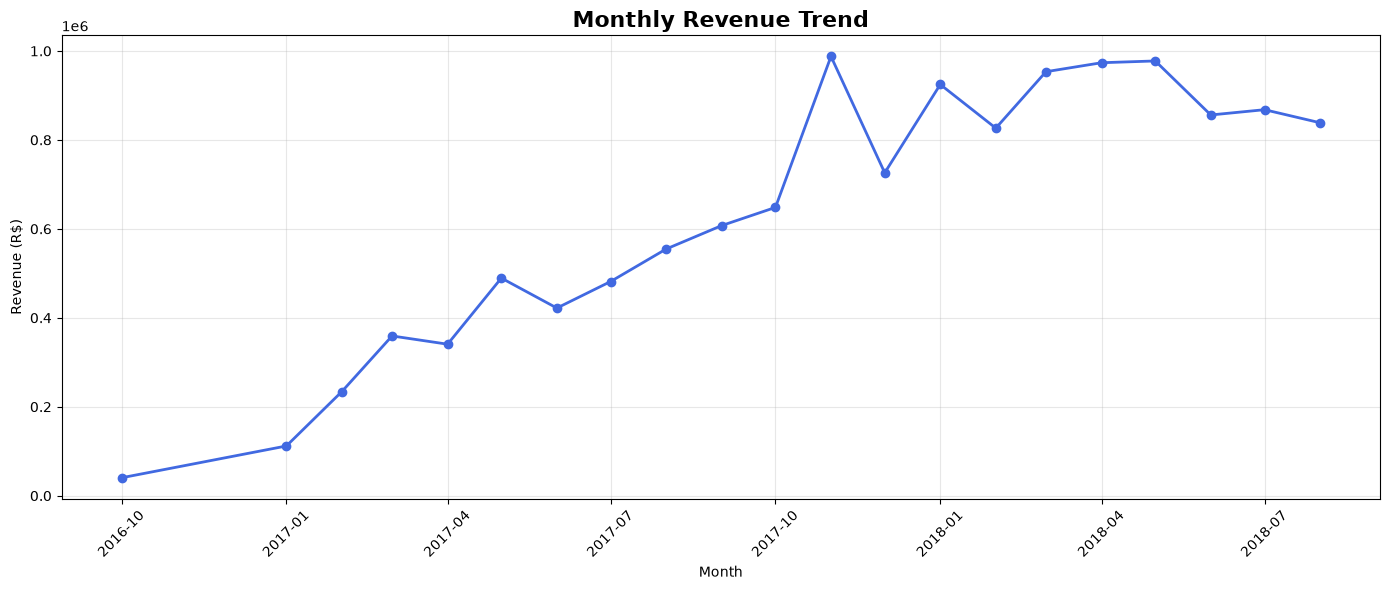

In [14]:
# Monthly Revenue Trend Visualization

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales_growth["year_month"],
    monthly_sales_growth["Revenue"],
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title(
    "Monthly Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue (R$)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

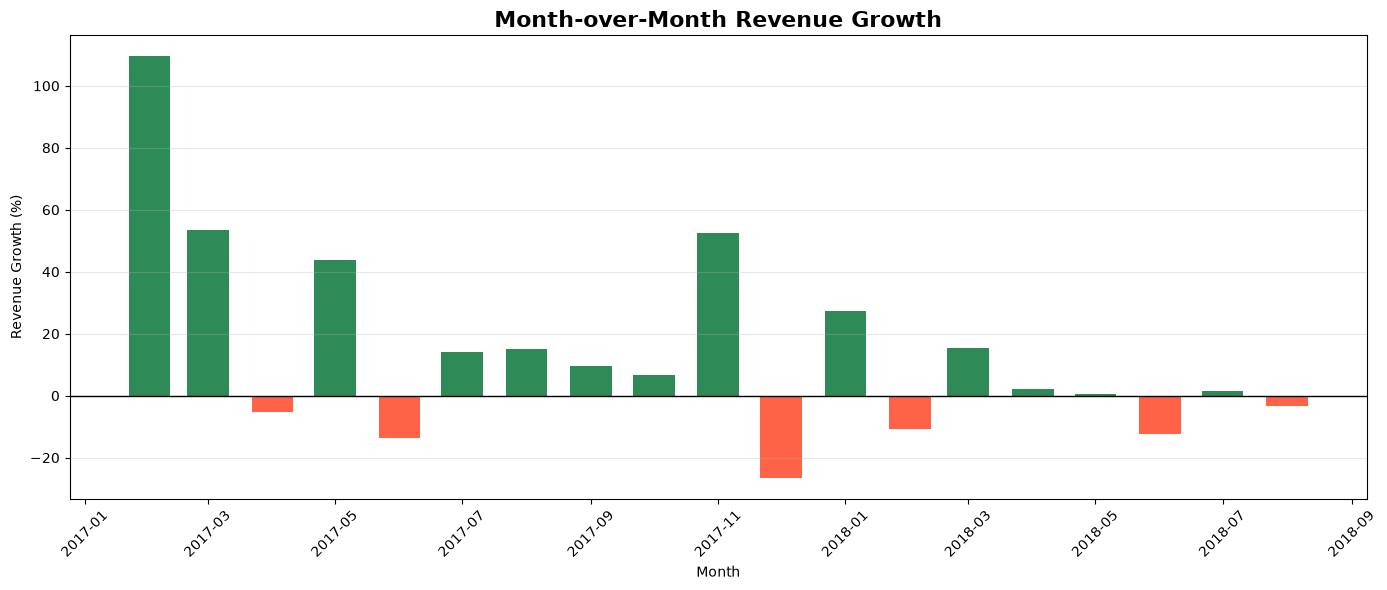

In [15]:
# Month-over-Month Revenue Growth Visualization

growth_colors = [
    "seagreen" if value >= 0 else "tomato"
    for value in monthly_sales_growth["MoM_Growth"]
]

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_sales_growth["year_month"],
    monthly_sales_growth["MoM_Growth"],
    width=20,
    color=growth_colors
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1
)

plt.title(
    "Month-over-Month Revenue Growth",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 12. הצגת מגמות מכירות — Sales Trend Visualization

לצורך המחשת השינויים בהכנסות לאורך זמן נוצרו שני תרשימים באמצעות ספריית Matplotlib.

### Monthly Revenue Trend

תרשים קווי המציג את ההכנסות החודשיות לאורך תקופת הניתוח.

התרשים מאפשר לזהות מגמות צמיחה, ירידות בהכנסות וחודשים בעלי פעילות חריגה.

### Month-over-Month Revenue Growth

תרשים עמודות המציג את שיעור השינוי בהכנסות בין חודשים עוקבים.

- **עמודות ירוקות:** צמיחה בהכנסות.
- **עמודות אדומות:** ירידה בהכנסות.
- **ערכים חסרים (NaN):** חודשים ללא השוואה חודשית תקינה.

### משמעות עסקית

שילוב שני התרשימים מאפשר להבחין בין היקף ההכנסות בפועל לבין קצב השינוי שלהן.

ניתוח זה עשוי לסייע בזיהוי תקופות צמיחה, ירידות בפעילות והזדמנויות לבדיקת גורמים המשפיעים על ביצועי המכירות.

In [16]:
# Year-over-Year Revenue Growth Analysis

# Prepare monthly revenue data
yoy_sales = monthly_sales_growth[
    ["year_month", "Revenue"]
].copy()

# Convert dates to datetime
yoy_sales["year_month"] = pd.to_datetime(
    yoy_sales["year_month"]
)

# Create previous-year matching dates
yoy_sales["Previous_Year_Month"] = (
    yoy_sales["year_month"] - pd.DateOffset(years=1)
)

# Create a lookup table for previous-year revenue
previous_year_sales = yoy_sales[
    ["year_month", "Revenue"]
].rename(
    columns={
        "year_month": "Previous_Year_Month",
        "Revenue": "Previous_Year_Revenue"
    }
)

# Match each month with the same month last year
yoy_sales = yoy_sales.merge(
    previous_year_sales,
    on="Previous_Year_Month",
    how="left"
)

# Calculate YoY growth percentage
yoy_sales["YoY_Growth"] = (
    (
        yoy_sales["Revenue"]
        - yoy_sales["Previous_Year_Revenue"]
    )
    / yoy_sales["Previous_Year_Revenue"]
) * 100

# Display results
display(
    yoy_sales[
        [
            "year_month",
            "Revenue",
            "Previous_Year_Revenue",
            "YoY_Growth"
        ]
    ].style.format({
        "Revenue": "{:,.2f}",
        "Previous_Year_Revenue": "{:,.2f}",
        "YoY_Growth": "{:+.2f}%"
    }, na_rep="N/A")
)

,year_month,Revenue,Previous_Year_Revenue,YoY_Growth
0,2016-10-01 00:00:00,"40,325.11",N/A,N/A
1,2017-01-01 00:00:00,"111,798.36",N/A,N/A
2,2017-02-01 00:00:00,"234,223.40",N/A,N/A
3,2017-03-01 00:00:00,"359,198.85",N/A,N/A
4,2017-04-01 00:00:00,"340,669.68",N/A,N/A
5,2017-05-01 00:00:00,"489,338.25",N/A,N/A
6,2017-06-01 00:00:00,"421,923.37",N/A,N/A
7,2017-07-01 00:00:00,"481,604.52",N/A,N/A
8,2017-08-01 00:00:00,"554,699.70",N/A,N/A
9,2017-09-01 00:00:00,"607,399.67",N/A,N/A


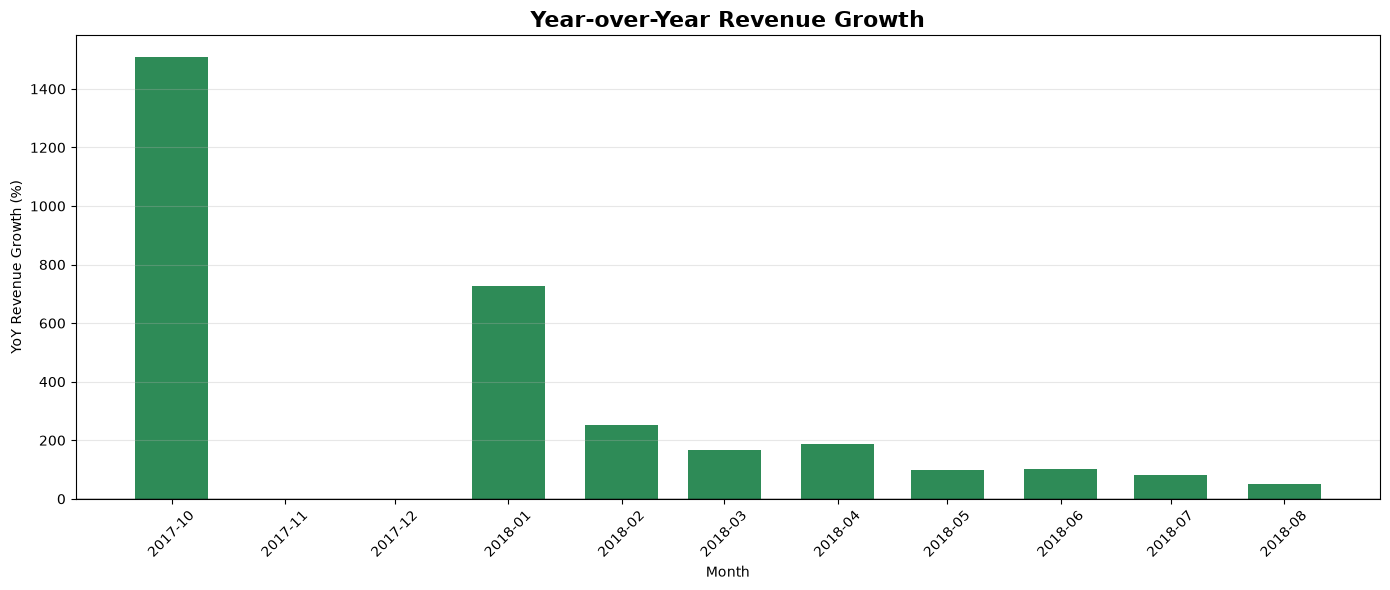

In [17]:
# Year-over-Year Revenue Growth Visualization

yoy_chart = yoy_sales.dropna(
    subset=["YoY_Growth"]
).copy()

colors = [
    "seagreen" if value >= 0 else "tomato"
    for value in yoy_chart["YoY_Growth"]
]

plt.figure(figsize=(14, 6))

plt.bar(
    yoy_chart["year_month"],
    yoy_chart["YoY_Growth"],
    width=20,
    color=colors
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1
)

plt.title(
    "Year-over-Year Revenue Growth",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("YoY Revenue Growth (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 13. ניתוח צמיחה שנתית — Year-over-Year (YoY)

בשלב זה בוצעה השוואה בין ההכנסות בכל חודש לבין ההכנסות בחודש המקביל בשנה הקודמת.

### מטרת הניתוח

מדד YoY מאפשר לבחון את השינוי בהכנסות לאורך שנה ולצמצם את השפעת העונתיות בהשוואה למדד הצמיחה החודשית (MoM).

### מתודולוגיה

1. הכנת נתוני ההכנסות החודשיות.
2. זיהוי החודש המקביל בשנה הקודמת באמצעות `DateOffset`.
3. התאמת נתוני ההכנסות באמצעות `merge`.
4. חישוב שיעור השינוי השנתי באחוזים.
5. הצגת התוצאות בטבלה ובתרשים עמודות.

### נוסחת החישוב

YoY = \frac{Revenue_{Current} - Revenue_{PreviousYear}}{Revenue_{PreviousYear}} \times 100

### מגבלות הניתוח

חודשים שלא קיימים עבורם נתונים מהחודש המקביל בשנה הקודמת אינם מקבלים ערך YoY.

בנוסף, הניתוח מבוסס על חודשים שעברו את סף הפעילות שנקבע בשלב סינון הנתונים.

### משמעות עסקית

ניתוח YoY מאפשר להעריך האם ההכנסות צומחות בהשוואה לתקופה המקבילה בשנה הקודמת, ולזהות שינויים בביצועים העסקיים לאורך זמן.

In [18]:
# Validate YoY growth against previous-year order volume

previous_year_orders = monthly_sales_growth[
    ["year_month", "Orders"]
].copy()

previous_year_orders = previous_year_orders.rename(
    columns={
        "year_month": "Previous_Year_Month",
        "Orders": "Previous_Year_Orders"
    }
)

yoy_validation = yoy_sales.merge(
    previous_year_orders,
    on="Previous_Year_Month",
    how="left"
)

display(
    yoy_validation[
        [
            "year_month",
            "Revenue",
            "Previous_Year_Revenue",
            "Previous_Year_Orders",
            "YoY_Growth"
        ]
    ].style.format({
        "Revenue": "{:,.2f}",
        "Previous_Year_Revenue": "{:,.2f}",
        "Previous_Year_Orders": "{:,.0f}",
        "YoY_Growth": "{:+.2f}%"
    }, na_rep="N/A")
)

,year_month,Revenue,Previous_Year_Revenue,Previous_Year_Orders,YoY_Growth
0,2016-10-01 00:00:00,"40,325.11",N/A,N/A,N/A
1,2017-01-01 00:00:00,"111,798.36",N/A,N/A,N/A
2,2017-02-01 00:00:00,"234,223.40",N/A,N/A,N/A
3,2017-03-01 00:00:00,"359,198.85",N/A,N/A,N/A
4,2017-04-01 00:00:00,"340,669.68",N/A,N/A,N/A
5,2017-05-01 00:00:00,"489,338.25",N/A,N/A,N/A
6,2017-06-01 00:00:00,"421,923.37",N/A,N/A,N/A
7,2017-07-01 00:00:00,"481,604.52",N/A,N/A,N/A
8,2017-08-01 00:00:00,"554,699.70",N/A,N/A,N/A
9,2017-09-01 00:00:00,"607,399.67",N/A,N/A,N/A


### בדיקת מהימנות של מדד YoY

בניתוח הצמיחה השנתית זוהו שיעורי צמיחה גבוהים במיוחד בחלק מהחודשים.

חשוב להדגיש כי שיעור צמיחה גבוה עשוי לנבוע מבסיס השוואה נמוך בשנה הקודמת, ולא בהכרח משיפור עסקי באותו היקף.

לכן, לפני הסקת מסקנות עסקיות, יש לבחון גם את מספר ההזמנות ואת היקף ההכנסות בתקופת ההשוואה.

חודשים ללא נתוני השוואה שנתיים מסומנים כנתונים חסרים (N/A), ואין לפרש אותם כצמיחה של 0%.

בדיקה זו תסייע להבחין בין צמיחה עסקית משמעותית לבין שיעורי שינוי המושפעים מבסיס השוואה קטן.

In [19]:
# Classify YoY comparisons by previous-year order volume

MIN_PREVIOUS_YEAR_ORDERS = 1000

yoy_validation["Comparison_Quality"] = np.select(
    [
        yoy_validation["Previous_Year_Orders"].isna(),
        yoy_validation["Previous_Year_Orders"] < MIN_PREVIOUS_YEAR_ORDERS
    ],
    [
        "No Comparison",
        "Low Base"
    ],
    default="Standard Comparison"
)

# Display validation results
display(
    yoy_validation[
        [
            "year_month",
            "Previous_Year_Orders",
            "YoY_Growth",
            "Comparison_Quality"
        ]
    ]
)

# Count comparison categories
print("YoY Comparison Quality Summary")

print(
    yoy_validation["Comparison_Quality"].value_counts()
)

,year_month,Previous_Year_Orders,YoY_Growth,Comparison_Quality
0,2016-10-01,NaN,NaN,No Comparison
1,2017-01-01,NaN,NaN,No Comparison
2,2017-02-01,NaN,NaN,No Comparison
3,2017-03-01,NaN,NaN,No Comparison
4,2017-04-01,NaN,NaN,No Comparison
5,2017-05-01,NaN,NaN,No Comparison
6,2017-06-01,NaN,NaN,No Comparison
7,2017-07-01,NaN,NaN,No Comparison
8,2017-08-01,NaN,NaN,No Comparison
9,2017-09-01,NaN,NaN,No Comparison


YoY Comparison Quality Summary
Comparison_Quality
No Comparison          12
Standard Comparison     7
Low Base                2
Name: count, dtype: int64


### 10. בדיקת מהימנות ההשוואה השנתית — YoY Validation

כדי לשפר את מהימנות ניתוח הצמיחה השנתית, נבדק מספר ההזמנות בחודש המקביל בשנה הקודמת.

לצורך הניתוח הוגדר סף עבודה של 1,000 הזמנות בחודש ההשוואה. מדובר בכלל אנליטי שנבחר לפרויקט, ולא בסף סטטיסטי מחייב.

ההשוואות חולקו לשלוש קטגוריות:

- **No Comparison:** לא קיימים נתונים לחודש המקביל בשנה הקודמת.
- **Low Base:** מספר ההזמנות בחודש ההשוואה נמוך מ־1,000.
- **Standard Comparison:** מספר ההזמנות בחודש ההשוואה הוא לפחות 1,000.

#### ממצאים מרכזיים

באוקטובר 2017 נרשמה צמיחה שנתית של 1,507.55%, אך בחודש המקביל בשנת 2016 בוצעו 265 הזמנות בלבד.

בינואר 2018 נרשמה צמיחה של 727.06%, כאשר בחודש המקביל בשנת 2017 בוצעו 750 הזמנות.

לפיכך, יש לפרש את שיעורי הצמיחה הגבוהים בזהירות ולהתחשב בהיקף הפעילות בתקופת הבסיס.

בחודשים פברואר–אוגוסט 2018 נרשמה צמיחה שנתית חיובית, לצד בסיס השוואה של יותר מ־1,000 הזמנות.

**מסקנה עסקית:** מומלץ להציג את שיעורי הצמיחה השנתית יחד עם איכות בסיס ההשוואה, כדי להימנע מהסקת מסקנות מטעות לגבי ביצועי המכירות.

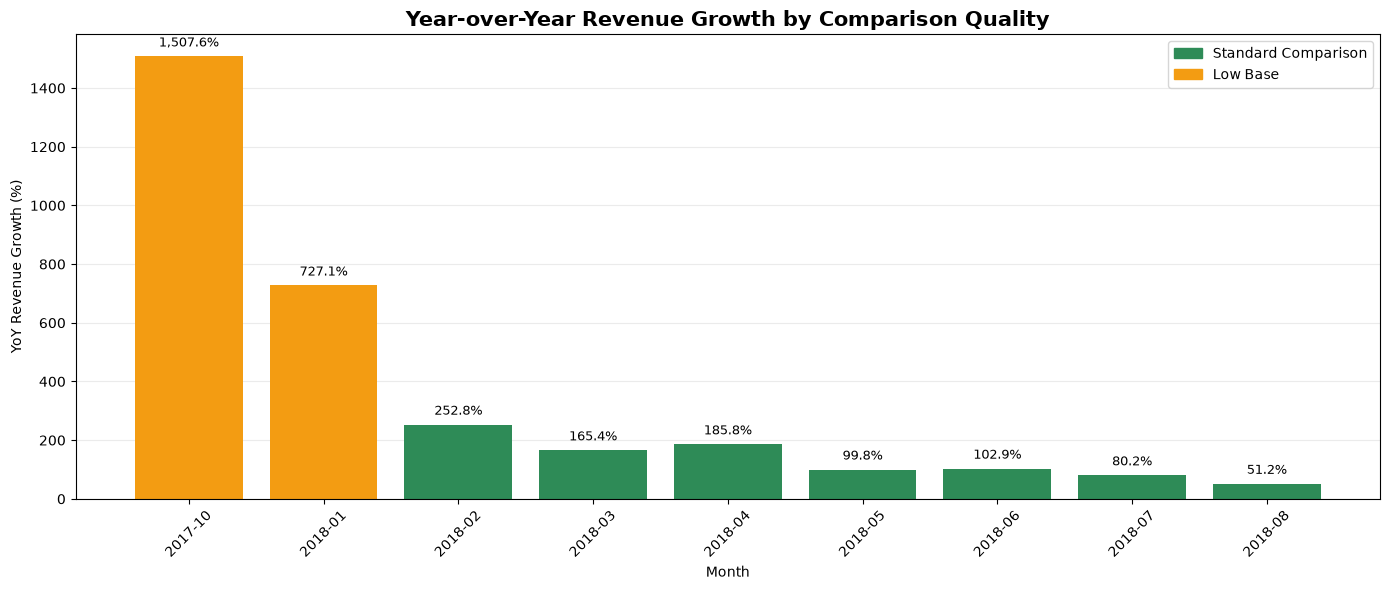

In [20]:
# Visualize YoY revenue growth by comparison quality

import matplotlib.pyplot as plt
import seaborn as sns

# Keep months with available YoY growth
yoy_chart = yoy_validation[
    yoy_validation["YoY_Growth"].notna()
].copy()

# Format month labels
yoy_chart["Month"] = (
    pd.to_datetime(yoy_chart["year_month"])
    .dt.strftime("%Y-%m")
)

# Assign colors based on comparison quality
colors = yoy_chart["Comparison_Quality"].map({
    "Standard Comparison": "#2E8B57",
    "Low Base": "#F39C12"
})

# Create chart
fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(
    yoy_chart["Month"],
    yoy_chart["YoY_Growth"],
    color=colors
)

# Display percentage above each bar
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Year-over-Year Revenue Growth by Comparison Quality",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("YoY Revenue Growth (%)")

plt.xticks(rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(color="#2E8B57", label="Standard Comparison"),
    Patch(color="#F39C12", label="Low Base")
])

plt.tight_layout()
plt.show()

### 11. הצגת צמיחה שנתית לפי איכות ההשוואה — YoY Growth Visualization

התרשים מציג את שיעור השינוי בהכנסות בהשוואה לחודש המקביל בשנה הקודמת, תוך הבחנה בין איכות בסיסי ההשוואה.

**סיווג ההשוואות:**

- **ירוק — Standard Comparison:** השוואה לחודש שבו בוצעו לפחות 1,000 הזמנות בשנה הקודמת.
- **כתום — Low Base:** השוואה לחודש שבו בוצעו פחות מ־1,000 הזמנות בשנה הקודמת.

חודשים ללא נתוני השוואה שנתיים אינם מוצגים בתרשים.

#### ממצאים מרכזיים

- באוקטובר 2017 נרשמה צמיחה של 1,507.55%, אך בסיס ההשוואה כלל 265 הזמנות בלבד.
- בינואר 2018 נרשמה צמיחה של 727.06%, על בסיס 750 הזמנות בינואר 2017.
- בחודשים פברואר–אוגוסט 2018 נרשמה צמיחה שנתית חיובית בכל החודשים שנבדקו.
- שיעור הצמיחה השנתית באוגוסט 2018 עמד על 51.18%.

#### מסקנה עסקית

הנתונים מצביעים על התרחבות משמעותית בפעילות המכירות לאורך תקופת הניתוח. עם זאת, יש להבחין בין צמיחה המבוססת על פעילות משמעותית בשנה הקודמת לבין צמיחה הנובעת מבסיס השוואה נמוך.

הבחנה זו מאפשרת להציג את ביצועי העסק באופן מדויק ואמין יותר.

In [21]:
# Export monthly sales trends for Streamlit Dashboard

from pathlib import Path

# Project root directory
project_root = Path.cwd().resolve()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

# Output directory
output_dir = project_root / "DATA" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare monthly sales data
sales_trends_export = monthly_sales_check[
    ["year_month", "Orders", "Revenue"]
].copy()

# Add validated YoY results
sales_trends_export = sales_trends_export.merge(
    yoy_validation[
        [
            "year_month",
            "YoY_Growth",
            "Comparison_Quality"
        ]
    ],
    on="year_month",
    how="left"
)

# Calculate MoM growth using consecutive calendar months
sales_trends_export = sales_trends_export.sort_values(
    "year_month"
).reset_index(drop=True)

sales_trends_export["year_month"] = pd.to_datetime(
    sales_trends_export["year_month"]
)

previous_month = (
    sales_trends_export["year_month"]
    .shift(1)
    + pd.DateOffset(months=1)
)

is_consecutive = (
    sales_trends_export["year_month"] == previous_month
)

sales_trends_export["MoM_Growth"] = (
    sales_trends_export["Revenue"].pct_change(
        fill_method=None
    ) * 100
).where(is_consecutive)

# Save CSV
output_file = output_dir / "sales_trends.csv"

sales_trends_export.to_csv(
    output_file,
    index=False
)

print("Sales trends exported successfully!")
print("File:", output_file)
print("Rows:", len(sales_trends_export))

display(sales_trends_export.tail())

Sales trends exported successfully!
File: C:\DATA SCINENCE\Ecommerce-Data-Analysis\DATA\processed\sales_trends.csv
Rows: 23


,year_month,Orders,Revenue,YoY_Growth,Comparison_Quality,MoM_Growth
18,2018-04-01,6798,"973,534.09",185.77,Standard Comparison,2.12
19,2018-05-01,6749,"977,544.69",99.77,Standard Comparison,0.41
20,2018-06-01,6099,"856,077.86",102.90,Standard Comparison,-12.43
21,2018-07-01,6159,"867,953.46",80.22,Standard Comparison,1.39
22,2018-08-01,6351,"838,576.64",51.18,Standard Comparison,-3.38


### 12. ייצוא נתוני מגמות המכירות — Sales Trends Export

בשלב זה הוכנה טבלת נתונים מסכמת לצורך שילוב ניתוח מגמות המכירות בלוח המחוונים האינטראקטיבי.

הטבלה כוללת את המשתנים הבאים:

- **year_month:** חודש הפעילות.
- **Orders:** מספר ההזמנות בחודש.
- **Revenue:** סך ההכנסות החודשיות ממכירת מוצרים.
- **MoM_Growth:** שיעור השינוי בהכנסות ביחס לחודש הקודם, כאשר קיימת רציפות בין החודשים.
- **YoY_Growth:** שיעור השינוי בהכנסות ביחס לחודש המקביל בשנה הקודמת.
- **Comparison_Quality:** סיווג איכות בסיס ההשוואה השנתית.

הנתונים נשמרו בקובץ `DATA/processed/sales_trends.csv`.

קובץ זה ישמש כמקור נתונים לעמוד **Sales Trends** ב־Streamlit Dashboard.

מטרת השלב היא להפריד בין תהליך עיבוד הנתונים ב־Python לבין שכבת הצגת הנתונים בלוח המחוונים.